# Pronóstico de la demanda eléctrica nacional (SIN Colombia)
### Proyecto Integrador — Deep Learning · Primera entrega (Fase 1)

Este notebook prepara los datos, hace el análisis exploratorio (EDA) y construye la **línea base** (modelo de persistencia)
para el proyecto de pronóstico de demanda eléctrica:

> L'Heureux, A., Grolinger, K., & Capretz, M. A. M. (2022). *Transformer-Based Model for Electrical Load Forecasting*. Energies, 15(14), 4993.

Los datos usados fueron descargados con la variable **DdaReal** (demanda real) para todos los agentes del mercado, en dos
tramos: 1 de enero – 31 de diciembre de 2024, y 1 de enero – 31 de octubre de 2025.

## 1. Configuración y carga de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})

# Si estás en Colab y quieres subir los archivos manualmente, descomenta:
# from google.colab import files
# uploaded = files.upload()

PATH_2024 = "Demandarealnacional894b4c1f-5776-421b-8f14-7cbfe8677e23.csv"  # 1 ene - 31 dic 2024
PATH_2025 = "Demandarealnacional5f838d41-8d2e-4e07-ac1a-52ee7c89d340.csv"  # 1 ene - 31 oct 2025


## 2. Carga y limpieza de los datos

Los archivos de XM traen la demanda **desagregada por 65 agentes** del mercado (regulado y no regulado), y para
un mismo mes pueden existir **varias versiones de liquidación** (`TX2` … `TX8`, `TXR`, `TXF`), que corresponden a
sucesivas revisiones que hace XM sobre el mismo periodo. Si no filtramos por versión, sumaríamos la misma hora varias
veces.

La estrategia es: para cada mes, quedarnos únicamente con la versión **más avanzada** disponible (dando prioridad a la
versión final `TXF` cuando existe), y luego sumar la demanda de los 65 agentes por hora para obtener la
**demanda nacional horaria**.

In [2]:
df = pd.concat([pd.read_csv(PATH_2024), pd.read_csv(PATH_2025)], ignore_index=True)
df['FechaHora'] = pd.to_datetime(df['FechaHora'])
df['mes'] = df['FechaHora'].dt.to_period('M')

print(f"Filas totales cargadas: {len(df):,}")
print(f"Agentes de mercado distintos: {df['CodigoSICAgente'].nunique()}")
print(f"Versiones de liquidación presentes: {sorted(df['Version'].unique())}")
df.head()


Filas totales cargadas: 2,257,704
Agentes de mercado distintos: 67
Versiones de liquidación presentes: ['TX2', 'TX3', 'TX4', 'TX5', 'TX6', 'TX7', 'TX8', 'TXF', 'TXR']


,CodigoVariable,FechaHora,CodigoSICAgente,TipoMercado,Version,Valor,UnidadMedida,CodigoDuracion,mes
0,DdaReal,2024-08-16 23:00:00,SOEC,No Regulado,TX4,79446.54,kWh,PT1H,2024-08
1,DdaReal,2024-08-16 22:00:00,SOEC,No Regulado,TX4,78546.20,kWh,PT1H,2024-08
2,DdaReal,2024-08-16 21:00:00,SOEC,No Regulado,TX4,88274.92,kWh,PT1H,2024-08
3,DdaReal,2024-08-16 20:00:00,SOEC,No Regulado,TX4,90236.97,kWh,PT1H,2024-08
4,DdaReal,2024-08-16 19:00:00,SOEC,No Regulado,TX4,89510.01,kWh,PT1H,2024-08


In [3]:
# Prioridad de versiones: la más final primero
prioridad = ['TXF', 'TXR', 'TX8', 'TX7', 'TX6', 'TX5', 'TX4', 'TX3', 'TX2']
rango = {v: i for i, v in enumerate(prioridad)}
df['rango'] = df['Version'].map(rango)

# Para cada mes, se identifica la mejor version disponible (menor rango) y se filtra
mejor_por_mes = df.groupby('mes')['rango'].min().rename('mejor_rango')
df = df.merge(mejor_por_mes, on='mes')
df_limpio = df[df['rango'] == df['mejor_rango']].copy()

print("Version seleccionada por mes:")
print(df_limpio.groupby('mes')['Version'].unique())
print(f"\nFilas tras eliminar versiones duplicadas: {len(df_limpio):,} (de {len(df):,} originales)")


Version seleccionada por mes:
mes
2024-01    [TX5]
2024-02    [TX6]
2024-03    [TX6]
2024-04    [TX5]
2024-05    [TX4]
2024-06    [TX5]
2024-07    [TX5]
2024-08    [TX4]
2024-09    [TX8]
2024-10    [TX7]
2024-11    [TX7]
2024-12    [TX7]
2025-01    [TX4]
2025-02    [TX4]
2025-03    [TX4]
2025-04    [TX5]
2025-05    [TX4]
2025-06    [TX3]
2025-07    [TX5]
2025-08    [TXF]
2025-09    [TXF]
2025-10    [TXF]
Freq: M, Name: Version, dtype: object

Filas tras eliminar versiones duplicadas: 1,436,328 (de 2,257,704 originales)


In [4]:
# Se suma la demanda de los 65 agentes por hora -> demanda nacional horaria
nacional = df_limpio.groupby('FechaHora')['Valor'].sum().reset_index()
nacional.columns = ['FechaHora', 'DemandaKWh']
nacional = nacional.sort_values('FechaHora').reset_index(drop=True)
nacional['DemandaMWh'] = nacional['DemandaKWh'] / 1000

# Verificacion de continuidad: no deben faltar horas
rango_completo = pd.date_range(nacional['FechaHora'].min(), nacional['FechaHora'].max(), freq='h')
faltantes = rango_completo.difference(nacional['FechaHora'])
print(f"Periodo: {nacional['FechaHora'].min()} a {nacional['FechaHora'].max()}")
print(f"Horas totales: {len(nacional):,}  |  Horas faltantes: {len(faltantes)}")

nacional.to_csv('demanda_nacional_horaria.csv', index=False)
nacional.describe()


Periodo: 2024-01-01 00:00:00 a 2025-10-31 23:00:00
Horas totales: 16,080  |  Horas faltantes: 0


,FechaHora,DemandaKWh,DemandaMWh
count,16080,1.608000e+04,16080.000000
mean,2024-11-30 23:30:00,9.257954e+06,9257.954059
min,2024-01-01 00:00:00,6.224061e+06,6224.061460
25%,2024-06-16 11:45:00,8.318539e+06,8318.538558
50%,2024-11-30 23:30:00,9.315562e+06,9315.562110
75%,2025-05-17 11:15:00,1.023415e+07,10234.152555
max,2025-10-31 23:00:00,1.166771e+07,11667.714170
std,NaN,1.090829e+06,1090.828563


## 3. Análisis exploratorio (EDA)

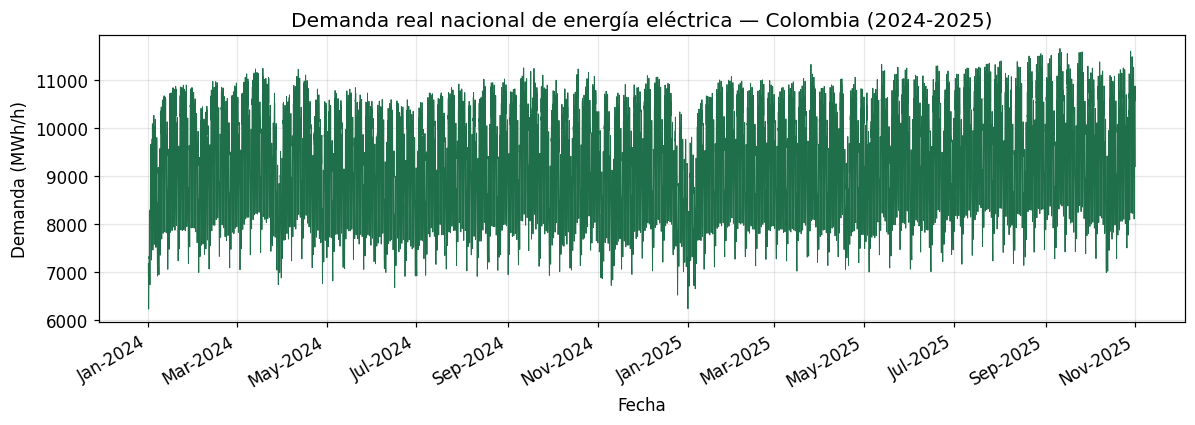

In [5]:
df_idx = nacional.set_index('FechaHora')
y = df_idx['DemandaMWh']

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, color='#1f6f4a', linewidth=0.6)
ax.set_title('Demanda real nacional de energía eléctrica — Colombia (2024-2025)')
ax.set_ylabel('Demanda (MWh/h)')
ax.set_xlabel('Fecha')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('fig1_serie_completa.png', dpi=160)
plt.show()


Se observa una estacionalidad diaria muy marcada (el rango entre el valle nocturno y el pico) y un **crecimiento
gradual** de la demanda entre 2024 y 2025, con una caída puntual muy fuerte alrededor de año nuevo (1 de enero,
festivo con demanda mínima del periodo).

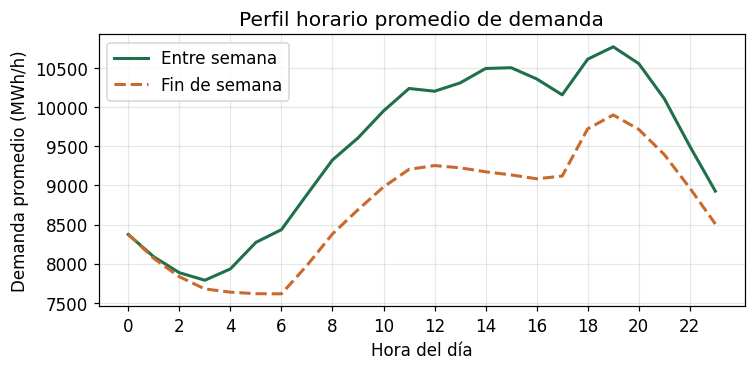

In [6]:
# Perfil horario promedio: entre semana vs fin de semana
tmp = df_idx.copy()
tmp['hora'] = tmp.index.hour
tmp['dow'] = tmp.index.dayofweek  # 0 = lunes
tmp['tipo_dia'] = np.where(tmp['dow'] < 5, 'Entre semana', 'Fin de semana')
perfil = tmp.groupby(['tipo_dia', 'hora'])['DemandaMWh'].mean().unstack(0)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(perfil.index, perfil['Entre semana'], label='Entre semana', color='#1f6f4a', linewidth=2)
ax.plot(perfil.index, perfil['Fin de semana'], label='Fin de semana', color='#c96a2b', linewidth=2, linestyle='--')
ax.set_title('Perfil horario promedio de demanda')
ax.set_xlabel('Hora del día'); ax.set_ylabel('Demanda promedio (MWh/h)')
ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.tight_layout()
plt.savefig('fig2_perfil_horario.png', dpi=160)
plt.show()


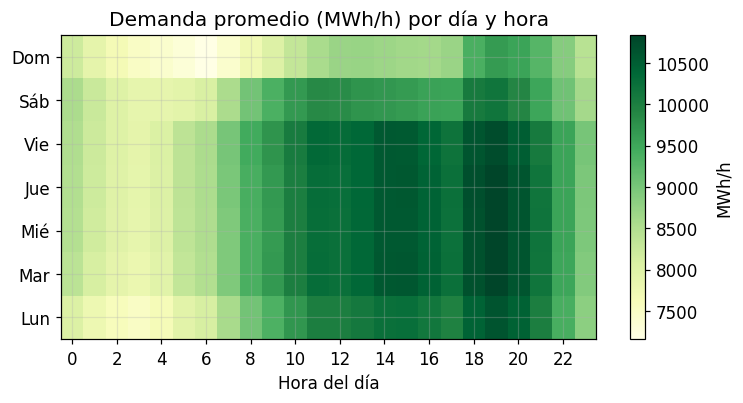

In [7]:
# Mapa de calor dia de la semana x hora
dias_es = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
heat = tmp.groupby(['dow', 'hora'])['DemandaMWh'].mean().unstack(0)

fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(heat.T.values, aspect='auto', cmap='YlGn', origin='lower')
ax.set_yticks(range(7)); ax.set_yticklabels(dias_es)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel('Hora del día'); ax.set_title('Demanda promedio (MWh/h) por día y hora')
cbar = plt.colorbar(im, ax=ax); cbar.set_label('MWh/h')
plt.tight_layout()
plt.savefig('fig3_heatmap_dia_hora.png', dpi=160)
plt.show()


**Lectura:** la demanda es más alta entre semana que los fines de semana, con un pico consistente entre las 6 p. m. y
las 8 p. m. (hora de mayor consumo residencial + comercial/industrial aún activo) y un valle en la madrugada (2-5 a. m.).
Estos dos patrones diario y semanal son justamente el tipo de señal de calendario que el módulo contextual del
artículo Transformer está diseñado para aprovechar.

## 4. Partición cronológica (train / test)

Para evitar fuga de información desde el futuro, la partición es estrictamente cronológica: las últimas 8 semanas
se reservan para prueba, y todo lo anterior se usa como entrenamiento (en la Fase 2 se separará además un bloque de
validación desde el final del entrenamiento).

In [8]:
TEST_DIAS = 56  # 8 semanas
test_start = df_idx.index.max() - pd.Timedelta(days=TEST_DIAS)

train = df_idx[df_idx.index < test_start]
test = df_idx[df_idx.index >= test_start]

print(f"Entrenamiento: {train.index.min()} -> {train.index.max()}  ({len(train):,} horas)")
print(f"Prueba:        {test.index.min()} -> {test.index.max()}  ({len(test):,} horas)")


Entrenamiento: 2024-01-01 00:00:00 -> 2025-09-05 22:00:00  (14,735 horas)
Prueba:        2025-09-05 23:00:00 -> 2025-10-31 23:00:00  (1,345 horas)


## 5. Línea base: modelo de persistencia

Se evalúan tres variantes:

- **Persistencia t-1h**: la demanda de la próxima hora es igual a la de la hora inmediatamente anterior.
- **Persistencia t-24h** (línea base oficial): la demanda de una hora es igual a la de la misma hora del día anterior.
- **Persistencia t-168h**: la demanda de una hora es igual a la de la misma hora, mismo día, de la semana anterior.

Las métricas usadas MAE, RMSE y MAPE son las mismas que reporta el artículo base.

In [9]:
def metricas(y_true, y_pred):
    err = y_true - y_pred
    mae = err.abs().mean()
    rmse = np.sqrt((err ** 2).mean())
    mape = (err.abs() / y_true.abs()).mean() * 100
    return mae, rmse, mape

pred_1 = y.shift(1)
pred_24 = y.shift(24)
pred_168 = y.shift(168)

mask_test = test.index
b1 = metricas(y.loc[mask_test], pred_1.loc[mask_test])
b24 = metricas(y.loc[mask_test], pred_24.loc[mask_test])
b168 = metricas(y.loc[mask_test], pred_168.loc[mask_test])

resultados = pd.DataFrame(
    [b1, b24, b168],
    columns=['MAE (MWh)', 'RMSE (MWh)', 'MAPE (%)'],
    index=['Persistencia t-1h', 'Persistencia t-24h (línea base oficial)', 'Persistencia t-168h']
).round(2)
resultados


,MAE (MWh),RMSE (MWh),MAPE (%)
Persistencia t-1h,274.04,329.57,2.92
Persistencia t-24h (línea base oficial),433.54,633.57,4.59
Persistencia t-168h,283.03,390.96,3.02


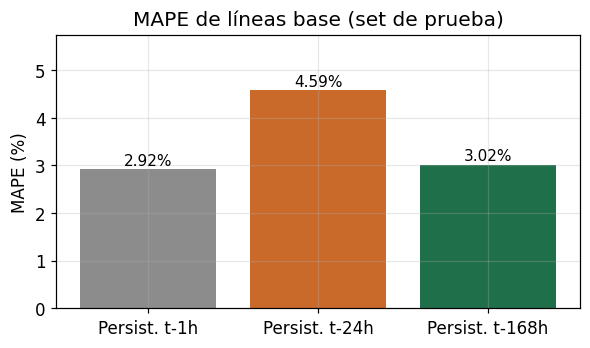

In [10]:
labels = ['Persist. t-1h', 'Persist. t-24h', 'Persist. t-168h']
mapes = [b1[2], b24[2], b168[2]]

fig, ax = plt.subplots(figsize=(5.5, 3.3))
bars = ax.bar(labels, mapes, color=['#8c8c8c', '#c96a2b', '#1f6f4a'])
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE de líneas base (set de prueba)')
ax.set_ylim(0, max(mapes) * 1.25)
for bar, v in zip(bars, mapes):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.08, f'{v:.2f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('fig5_mape_baselines.png', dpi=160)
plt.show()


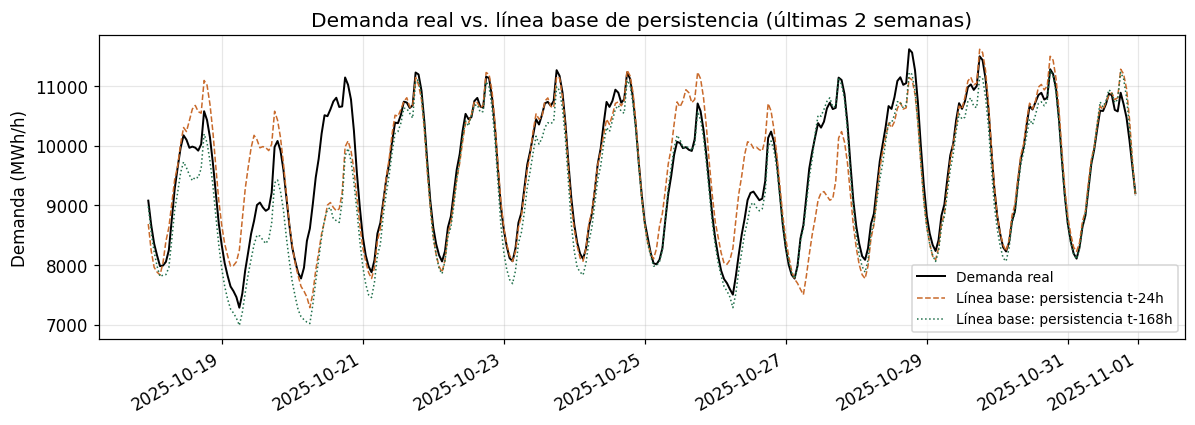

In [11]:
zoom = df_idx.index >= (df_idx.index.max() - pd.Timedelta(days=14))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index[zoom], y.values[zoom], label='Demanda real', color='black', linewidth=1.3)
ax.plot(y.index[zoom], pred_24.values[zoom], label='Línea base: persistencia t-24h', color='#c96a2b', linewidth=1, linestyle='--')
ax.plot(y.index[zoom], pred_168.values[zoom], label='Línea base: persistencia t-168h', color='#1f6f4a', linewidth=1, linestyle=':')
ax.set_title('Demanda real vs. línea base de persistencia (últimas 2 semanas)')
ax.set_ylabel('Demanda (MWh/h)')
ax.legend(fontsize=9)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('fig4_baseline_zoom.png', dpi=160)
plt.show()


**Conclusión de la línea base:** la persistencia semanal (t-168h) es notablemente más precisa (MAPE ≈ 3.0 %) que la
persistencia diaria (t-24h, MAPE ≈ 4.6 %), lo que confirma que el patrón semana/fin de semana es muy fuerte en esta
serie. Se adopta **t-24h como línea base oficial** por ser la sugerida explícitamente en la guía del curso para un
horizonte de 24 horas, y se deja t-168h como referencia adicional de contraste.


## 6. Resumen de estadísticas para el informe

In [12]:
df_idx['anio'] = df_idx.index.year
df_idx['mes_num'] = df_idx.index.month
comparable = df_idx[df_idx['mes_num'] <= 10]  # enero-octubre en ambos años
promedio_anual = comparable.groupby('anio')['DemandaMWh'].mean()
crecimiento = (promedio_anual[2025] / promedio_anual[2024] - 1) * 100

print(f"Horas totales en la serie: {len(df_idx):,}  ({len(df_idx)/24:.0f} días)")
print(f"Demanda promedio: {y.mean():,.0f} MWh/h")
print(f"Demanda mínima:   {y.min():,.0f} MWh/h  el {y.idxmin()}")
print(f"Demanda máxima:   {y.max():,.0f} MWh/h  el {y.idxmax()}")
print(f"Crecimiento demanda promedio ene-oct 2025 vs. 2024: {crecimiento:.1f}%")


Horas totales en la serie: 16,080  (670 días)
Demanda promedio: 9,258 MWh/h
Demanda mínima:   6,224 MWh/h  el 2024-01-01 06:00:00
Demanda máxima:   11,668 MWh/h  el 2025-09-10 19:00:00
Crecimiento demanda promedio ene-oct 2025 vs. 2024: 2.0%
